# 02 — Feature EDA & Data Quality (NHANES 2005–2018)

依照專案的 `build_features.py` 與 `feature_dictionary.csv`，進行 **Feature Overview → Feature Selection → Missingness → Cross-Cycle Stability → Feature–Target Relationships → Correlation（選用）**。

**重要定義**：`NaN` = 真正缺失；`-1` = 問卷不適用（Not Applicable），兩者不能混為一談。所有標籤比例均為**未加權樣本比例**，不等於美國人口盛行率；EDA 關聯不能解釋為因果。此 Notebook 只讀取既有資料，不修改 Pipeline。

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'outputs/features/features_2005_2018.csv.gz').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('找不到 outputs/features/features_2005_2018.csv.gz；請從專案根目錄或 data_analysis/ 執行')
FEAT = ROOT / 'outputs/features'
OUT = ROOT / 'outputs/data_analysis'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
CYCLES = ['2005-06', '2007-08', '2009-10', '2011-12', '2013-14', '2015-16', '2017-18']
BLUE, ORANGE = '#91ACC5', '#E9783D'

frame = pd.read_csv(FEAT / 'features_2005_2018.csv.gz')
dic = pd.read_csv(FEAT / 'feature_dictionary.csv')
assert {'column','status','kind','type','missing','not_applicable','max_cycle_missing'}.issubset(dic.columns)
assert {'cycle','depression'}.issubset(frame.columns)
assert frame.depression.isin([0,1]).all()
kept = dic.loc[dic.status.eq('kept')].copy()
features = kept.column.tolist()
assert set(features).issubset(frame.columns), 'Dictionary 與最終特徵表的欄位不一致'
assert all(f'miss_{c}' in dic.columns for c in CYCLES)
print('Final samples:', f'{len(frame):,}', '| final features:', len(features), '| columns:', len(frame.columns))
print('Cycle counts:')
print(frame.cycle.value_counts().reindex(CYCLES).to_string())
print('Depression positive:', int(frame.depression.sum()), f'({frame.depression.mean()*100:.2f}%, unweighted)')


Final samples: 33,498 | final features: 317 | columns: 325
Cycle counts:
cycle
2005-06    3975
2007-08    5104
2009-10    5222
2011-12    4594
2013-14    4995
2015-16    4829
2017-18    4779
Depression positive: 2970 (8.87%, unweighted)


## 1. Feature Overview

最終特徵數量、依資料類型與建構方式分類；注意 `type` 是 Pipeline 定義的欄位類型，不代表完全對應資料的統計測量尺度。

,Metric,Count
0,Final participants,33498
1,Final features,317
2,Continuous,155
3,Categorical,162
4,Not-applicable features (-1 present),21


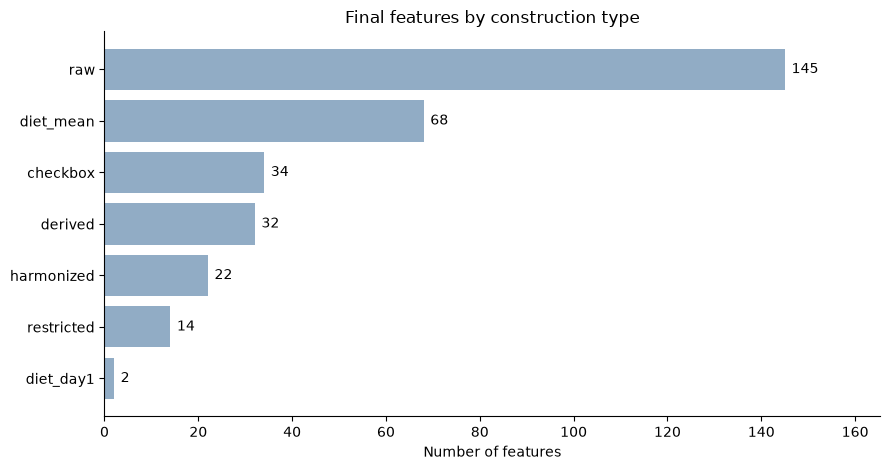

In [10]:
overview = pd.DataFrame({
    'Metric': ['Final participants', 'Final features', 'Continuous', 'Categorical', 'Not-applicable features (-1 present)'],
    'Count': [len(frame), len(features), int(kept.type.eq('continuous').sum()),
              int(kept.type.eq('categorical').sum()), int(kept.not_applicable.gt(0).sum())]
})
display(overview)
kind_counts = kept.kind.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9,4.8))
ax.barh(kind_counts.index, kind_counts.values, color=BLUE)
for i, value in enumerate(kind_counts.values):
    ax.text(value + max(kind_counts.values)*0.01, i, str(value), va='center')
ax.set_xlim(0, max(kind_counts.values)*1.14)
ax.set_title('Final features by construction type')
ax.set_xlabel('Number of features')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(FIG/'05_feature_overview.png',dpi=250,bbox_inches='tight'); plt.show()
kept.groupby(['kind','type']).size().rename('count').reset_index().to_csv(OUT/'feature_overview.csv',index=False)


## 2. Feature Selection Summary（有憑據的計數）

資料處理不是每一步都「直接刪除」變數：`step3_cycle_overlap.py` 標記七期出現狀態，`step4_rename.py` 合併改名變數；`build_features.py` 另建衍生欄位並處理子抽樣實驗室檢查。因此**不可把不同處理階段的計數誤畫成連續減法 Funnel**。

本節使用 `feature_catalog.csv`（若存在）呈現候選類別與跨期覆蓋，並用最終 `feature_dictionary.csv` 顯示 `kept`、`over_threshold`、`subsample_lab`，避免捏造中間篩選數字。

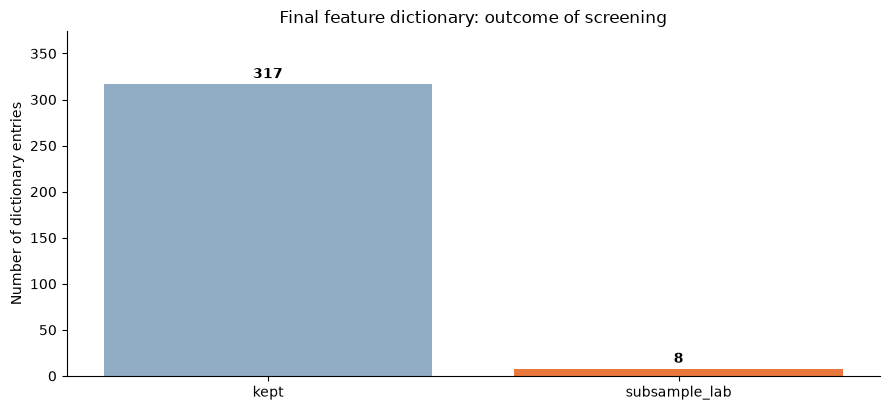

Final status count:


,count
status,
kept,317
subsample_lab,8


Candidate variable categories (module–variable entries):


,count
category,
feature,1459
process,74
comment_code,54
id,49
unit_duplicate,32
renamed,22
weight,22
outcome,10
outcome_proxy,5


Tagged as features present in all 7 cycles: 649


In [11]:
status_count = dic.status.value_counts()
fig, ax = plt.subplots(figsize=(9,4.2))
bars = ax.bar(status_count.index, status_count.values, color=[BLUE if s=='kept' else ORANGE for s in status_count.index])
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+max(status_count)*0.02,
            str(int(b.get_height())), ha='center', fontweight='bold')
ax.set_ylim(0,max(status_count)*1.18)
ax.set_ylabel('Number of dictionary entries')
ax.set_title('Final feature dictionary: outcome of screening')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(FIG/'06_feature_selection_status.png', dpi=250,bbox_inches='tight'); plt.show()
print('Final status count:'); display(status_count.rename('count').to_frame())

catalog_path = ROOT/'outputs/feature_catalog.csv'
if catalog_path.exists():
    catalog = pd.read_csv(catalog_path)
    print('Candidate variable categories (module–variable entries):')
    display(catalog.category.value_counts().rename('count').to_frame())
    if 'in_all_0518' in catalog.columns:
        print('Tagged as features present in all 7 cycles:', int(catalog.in_all_0518.fillna(False).astype(bool).sum()))
else:
    print('未找到 outputs/feature_catalog.csv；只呈現最終 Dictionary 統計，避免推估初始候選數量。')
status_count.rename_axis('status').reset_index(name='count').to_csv(OUT/'feature_selection_status.csv',index=False)


## 3. Missing Rate Analysis

使用 `feature_dictionary.csv` 的 `missing` 與 `miss_<cycle>`：**真正缺失（NaN）**。`not_applicable` 另列為 -1 的比例。資料 Pipeline 的規則：只要任一 Cycle 的真正缺失率 **>20%**，該特徵即不放進最終主表（子樣本 labs 另存）。

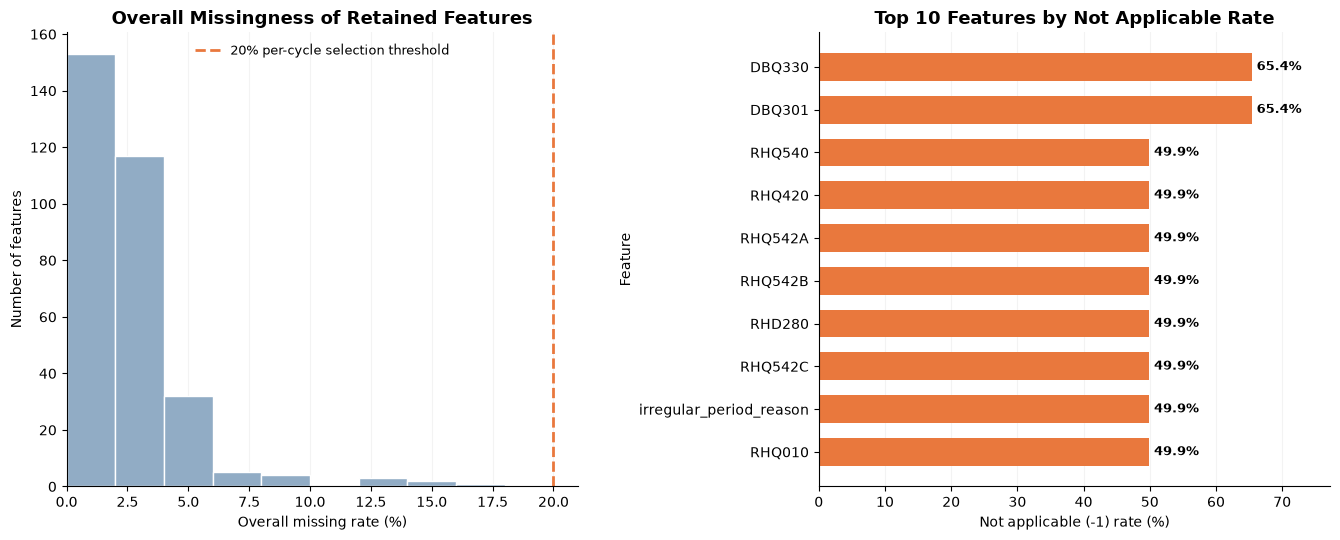

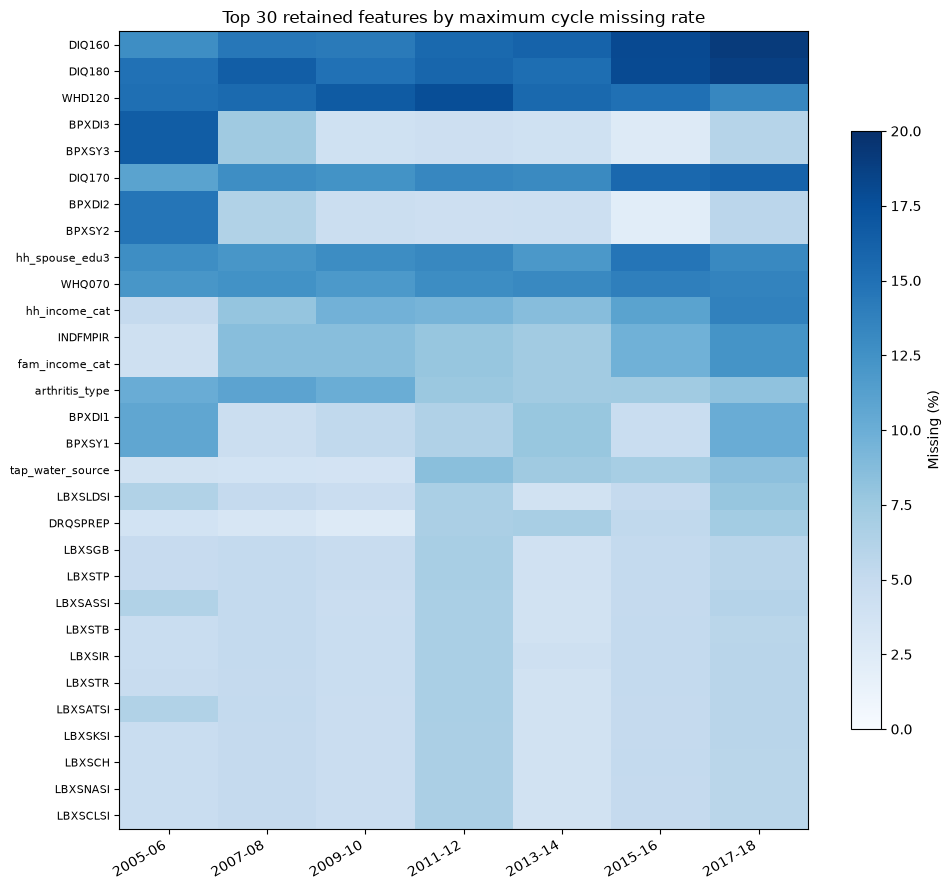

Max missing rate among retained features: 19.08%


In [12]:

# Missing Rate Analysis
# Left: overall missingness
# Right: top 10 features by not-applicable rate

miss_cols = [f'miss_{c}' for c in CYCLES]
missing_matrix = kept.set_index('column')[miss_cols].astype(float)

assert (missing_matrix.max(axis=1) <= 0.20001).all(), \
    "Retained features exceed the 20% per-cycle cutoff"

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))

# -----------------------------------
# Left: Overall Missing Rate
# -----------------------------------
ax = axes[0]

missing_pct = kept['missing'].astype(float) * 100

ax.hist(
    missing_pct,
    bins=np.arange(0, 22, 2),
    color=BLUE,
    edgecolor='white'
)

ax.axvline(
    20,
    color=ORANGE,
    linestyle='--',
    linewidth=2,
    label='20% per-cycle selection threshold'
)

ax.set_title(
    'Overall Missingness of Retained Features',
    fontsize=13,
    fontweight='bold'
)
ax.set_xlabel('Overall missing rate (%)')
ax.set_ylabel('Number of features')
ax.set_xlim(0, 21)
ax.legend(frameon=False, fontsize=9)

# -----------------------------------
# Right: Top 10 Not Applicable Rates
# -----------------------------------
ax = axes[1]

top_na = (
    kept[['column', 'not_applicable']]
    .copy()
    .assign(
        na_pct=lambda d:
        pd.to_numeric(d['not_applicable']) * 100
    )
    .sort_values('na_pct', ascending=False)
    .head(10)
    .sort_values('na_pct', ascending=True)
)

bars = ax.barh(
    top_na['column'],
    top_na['na_pct'],
    color=ORANGE,
    height=0.65
)

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%',
        va='center',
        fontsize=9,
        fontweight='bold'
    )

ax.set_title(
    'Top 10 Features by Not Applicable Rate',
    fontsize=13,
    fontweight='bold'
)
ax.set_xlabel('Not applicable (-1) rate (%)')
ax.set_ylabel('Feature')
ax.set_xlim(0, max(top_na['na_pct']) * 1.18)

# -----------------------------------
# Common formatting
# -----------------------------------
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', alpha=0.15)
    ax.set_axisbelow(True)

fig.tight_layout(w_pad=3)

fig.savefig(
    FIG / '07_missing_vs_not_applicable.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Most missing features across cycles; all retained features fit <=20% by policy
ordered = missing_matrix.max(axis=1).sort_values(ascending=False).head(30).index
heat = missing_matrix.loc[ordered].to_numpy() * 100
fig, ax = plt.subplots(figsize=(10,9))
im = ax.imshow(heat,aspect='auto',cmap='Blues',vmin=0,vmax=20)
ax.set_yticks(range(len(ordered)),ordered,fontsize=8)
ax.set_xticks(range(7),CYCLES,rotation=30,ha='right')
ax.set_title('Top 30 retained features by maximum cycle missing rate')
fig.colorbar(im,ax=ax,label='Missing (%)',shrink=.75)
fig.tight_layout(); fig.savefig(FIG/'08_missing_by_cycle_heatmap.png',dpi=250,bbox_inches='tight'); plt.show()
missing_matrix.rename(columns=dict(zip(miss_cols,CYCLES))).to_csv(OUT/'feature_cycle_missing_rates.csv')
print('Max missing rate among retained features:',f'{100*missing_matrix.to_numpy().max():.2f}%')


## 4. Cross-Cycle Feature Stability

比較不同 Cycle 的**實際觀察分布**，著重資料差異而非因果推論。特別注意 `sleep_hours` 在 2015 年起的問法變化；即使已保留，也未必能當成完全相同測量尺度。若該欄位不存在，會跳過而不是偷換成其他變數。

連續變數顯示中位數與四分位距；吸菸狀態顯示有效觀察樣本中的目前吸菸比例。不同年度的差異可能同時反映問卷修改、抽樣組成及真實趨勢。

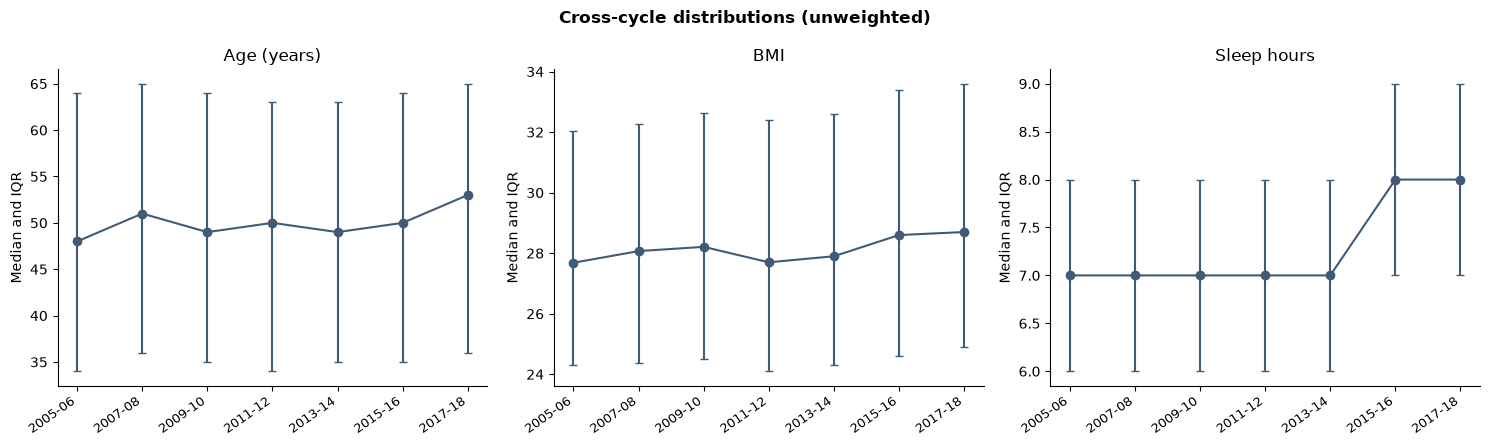

In [16]:
candidate_numeric = [('RIDAGEYR','Age (years)'),('BMXBMI','BMI'),('sleep_hours','Sleep hours')]
CYCLES = [
    '2005-06', '2007-08', '2009-10',
    '2011-12', '2013-14', '2015-16',
    '2017-18'
]
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
summary_rows=[]
for ax,(col,display_name) in zip(axes,candidate_numeric):
    if col not in frame.columns:
        ax.text(.5,.5,f'{col} not in final table',ha='center',va='center',transform=ax.transAxes)
        ax.set_axis_off();continue
    temp = frame[['cycle',col]].copy()
    temp[col] = pd.to_numeric(temp[col],errors='coerce').replace(-1,np.nan)
    g = temp.groupby('cycle')[col]
    med = g.median().reindex(CYCLES); q1=g.quantile(.25).reindex(CYCLES); q3=g.quantile(.75).reindex(CYCLES)
    n = g.count().reindex(CYCLES)
    summary_rows.extend([dict(feature=col,cycle=c,n=int(n.loc[c]),median=med.loc[c],q1=q1.loc[c],q3=q3.loc[c]) for c in CYCLES])
    xx=np.arange(7)
    ax.errorbar(xx,med,yerr=np.vstack([(med-q1).clip(lower=0),(q3-med).clip(lower=0)]),fmt='o-',color='#405B76',capsize=3)
    ax.set_xticks(
        xx,
        CYCLES,
        rotation=35,
        ha='right',
        fontsize=9
    )
    ax.set_title(display_name);ax.set_ylabel('Median and IQR')
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Cross-cycle distributions (unweighted)',fontweight='bold')
fig.tight_layout();fig.savefig(FIG/'09_cross_cycle_stability.png',dpi=250,bbox_inches='tight');plt.show()
pd.DataFrame(summary_rows).to_csv(OUT/'cross_cycle_numeric_summary.csv',index=False)


## 5. Feature–Target Relationships

這一節不做模型選特徵，只做描述性 EDA：Age、BMI 的分布及 Sex、Smoking 的 label 比例。**每個分組分母都是該欄位非缺失且有效的受訪者**。相關性不等於因果，也不是時間上未來發病的預測證明。

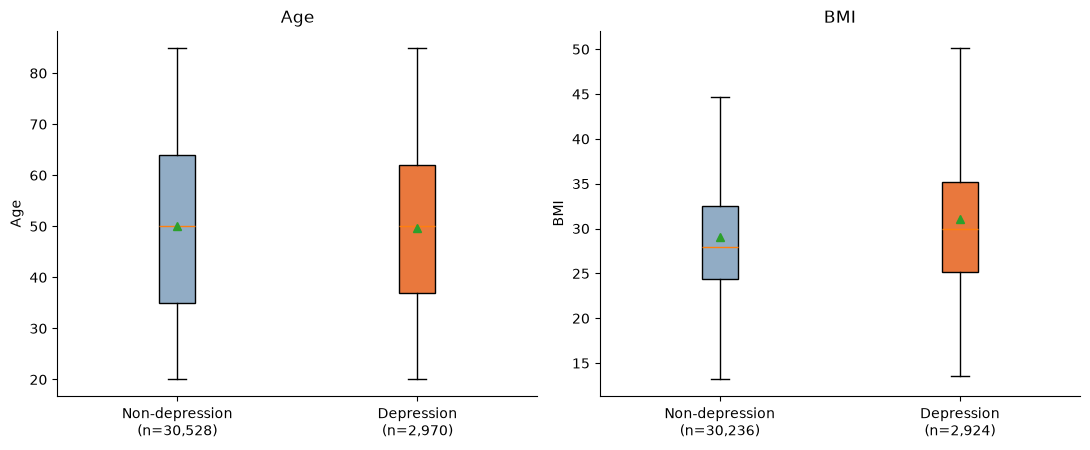

,feature,category,n,positive,rate_pct
0,Sex,Male,16729,1102,6.587363
1,Sex,Female,16769,1868,11.139603
2,Smoking,Never,18286,1195,6.535054
3,Smoking,Former,8224,667,8.110409
4,Smoking,Current,6970,1108,15.896700


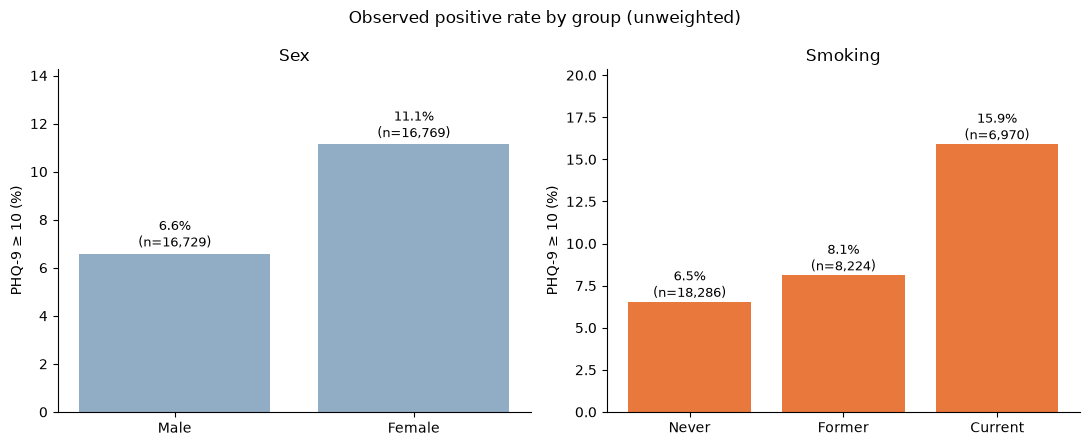

In [14]:
fig, axes=plt.subplots(1,2,figsize=(11,4.6))
for ax,(col,title) in zip(axes,[('RIDAGEYR','Age'),('BMXBMI','BMI')]):
    if col not in frame:
        ax.text(.5,.5,f'{col} not found',ha='center',va='center',transform=ax.transAxes);continue
    z=pd.to_numeric(frame[col],errors='coerce').replace(-1,np.nan)
    groups=[z.loc[frame.depression.eq(k)].dropna() for k in (0,1)]
    if not all(len(g) for g in groups): continue
    bp=ax.boxplot(groups,tick_labels=[f'Non-depression\n(n={len(groups[0]):,})',f'Depression\n(n={len(groups[1]):,})'],
                  showfliers=False,patch_artist=True,showmeans=True)
    for patch,color in zip(bp['boxes'],[BLUE,ORANGE]):patch.set_facecolor(color)
    ax.set_title(title);ax.set_ylabel(title);ax.spines[['top','right']].set_visible(False)
fig.tight_layout();fig.savefig(FIG/'10_age_bmi_by_target.png',dpi=250,bbox_inches='tight');plt.show()

rates=[]
if 'RIAGENDR' in frame:
    sex=pd.to_numeric(frame.RIAGENDR,errors='coerce').map({1:'Male',2:'Female'})
    for category in ['Male','Female']:
        mask=sex.eq(category);rates.append(dict(feature='Sex',category=category,n=int(mask.sum()),positive=int(frame.loc[mask,'depression'].sum())))
if 'smoking_status' in frame:
    smoke=pd.to_numeric(frame.smoking_status,errors='coerce').map({0:'Never',1:'Former',2:'Current'})
    for category in ['Never','Former','Current']:
        mask=smoke.eq(category);rates.append(dict(feature='Smoking',category=category,n=int(mask.sum()),positive=int(frame.loc[mask,'depression'].sum())))
rate_df=pd.DataFrame(rates)
if not rate_df.empty:
    rate_df['rate_pct']=100*rate_df.positive/rate_df.n
    display(rate_df)
    fig,axes=plt.subplots(1,2,figsize=(11,4.5))
    for ax,(feature,color) in zip(axes,[('Sex',BLUE),('Smoking',ORANGE)]):
        sub=rate_df[rate_df.feature.eq(feature)]
        if sub.empty:continue
        bars=ax.bar(sub.category,sub.rate_pct,color=color)
        for bar,r in zip(bars,sub.itertuples()):
            ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.3,f'{r.rate_pct:.1f}%\n(n={r.n:,})',ha='center',fontsize=9)
        ax.set_ylim(0,max(sub.rate_pct)*1.28)
        ax.set_title(feature);ax.set_ylabel('PHQ-9 ≥ 10 (%)')
        ax.spines[['top','right']].set_visible(False)
    fig.suptitle('Observed positive rate by group (unweighted)')
    fig.tight_layout();fig.savefig(FIG/'11_categorical_target_rates.png',dpi=250,bbox_inches='tight');plt.show()
rate_df.to_csv(OUT/'feature_target_rates.csv',index=False)


## 6. Correlation Analysis（選用）

只取字典標註 `continuous`、資料表確實存在的欄位；在計算 Spearman correlation 前先把 `-1` 當不適用排除。展示最多 16 個有足夠非缺失觀察與變異的欄位，並非全部 317 個欄位的完整矩陣。這裡的欄位選擇**不使用 depression 標籤**，避免誤導為模型選特徵程序。

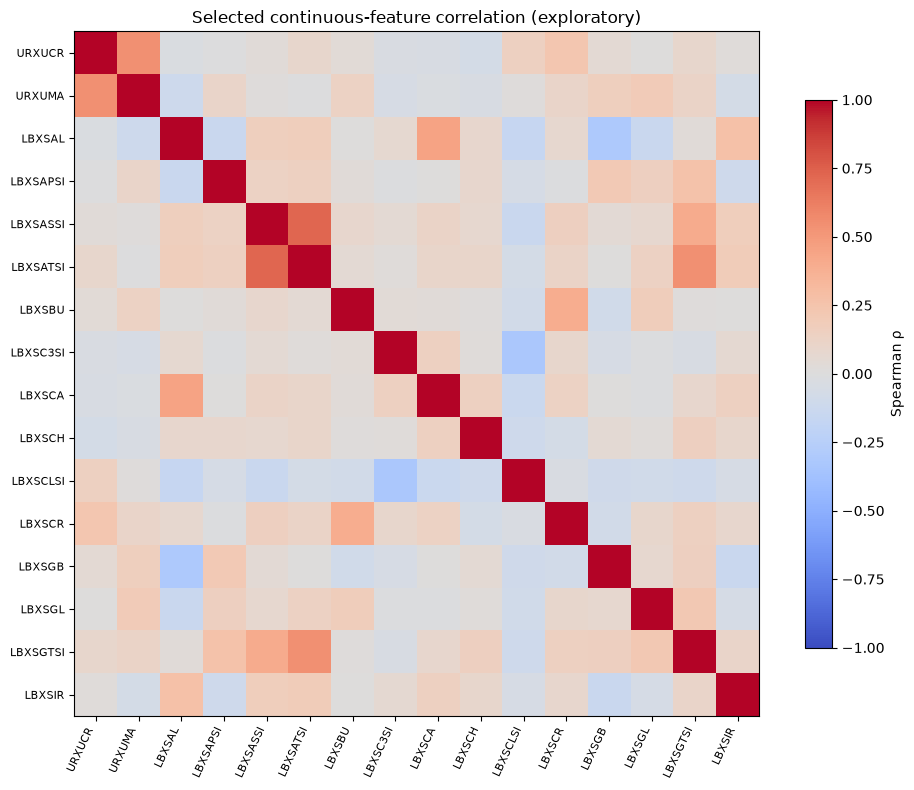

In [15]:
continuous = kept.loc[kept.type.eq('continuous'),'column'].tolist()
selected=[]
for col in continuous:
    if col not in frame: continue
    s=pd.to_numeric(frame[col],errors='coerce').replace(-1,np.nan)
    if s.notna().sum() >= .8*len(frame) and s.nunique(dropna=True) >= 6:
        selected.append(col)
    if len(selected)>=16:break
if len(selected)>=2:
    numeric=frame[selected].apply(pd.to_numeric,errors='coerce').replace(-1,np.nan)
    corr=numeric.corr(method='spearman',min_periods=100)
    fig,ax=plt.subplots(figsize=(10,8))
    im=ax.imshow(corr.to_numpy(),cmap='coolwarm',vmin=-1,vmax=1)
    ax.set_xticks(range(len(selected)),selected,rotation=65,ha='right',fontsize=8)
    ax.set_yticks(range(len(selected)),selected,fontsize=8)
    fig.colorbar(im,ax=ax,label='Spearman ρ',shrink=.8)
    ax.set_title('Selected continuous-feature correlation (exploratory)')
    fig.tight_layout();fig.savefig(FIG/'12_selected_feature_correlation.png',dpi=250,bbox_inches='tight');plt.show()
    corr.to_csv(OUT/'selected_feature_correlation.csv')
else:
    print('可用且符合條件的 continuous 特徵少於兩個，跳過 correlation plot。')


## 簡報使用建議與限制

- Slide A：`05_feature_overview.png` + `06_feature_selection_status.png`，清楚區分變數篩選與衍生特徵。
- Slide B：`07_missing_vs_not_applicable.png` + `08_missing_by_cycle_heatmap.png`。
- Slide C：`09_cross_cycle_stability.png`，搭配問卷定義變更的說明。
- Slide D：`10_age_bmi_by_target.png` + `11_categorical_target_rates.png`。
- `12_selected_feature_correlation.png` 可放補充頁。

**限制**：這些圖表使用未加權樣本；年份差異並不能直接歸因於 Harmonization 失敗；資料觀察結果不代表因果。若要使用特徵–標籤關係進行模型選特徵，必須在 Train fold 內重新執行，避免資料洩漏。